In [1]:
display("text/html", "<style>.container { width:100% !important; }</style>")

# Let's take a look at the Pigot data

In [2]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM

In [3]:
Plots.theme(:dao)

In [4]:
include("./diversity-simulator.jl")
using .dsim

In [5]:
pal = cgrad(:tol_muted);
cpal10 = [pal[i] for i in 0.0:1/46:1]

In [6]:
length(cpal10)

47

Import the birds. This is one of many.

In [7]:
read_data = CSV.read("./Pigot2025/Pigot2025/EmpiricalData/Coccolithophores_Individual.csv", DataFrame)
gd = groupby(read_data, :Site)

Row,Site,Binomial,Body_Mass,N
,String15,String,Int64,Int64
1,1_37.54,Acanthoica sp. cf. quattraspina,58,20
2,1_37.54,Anoplosolenia sp. cf. brasiliensis,30,360
3,1_37.54,Braarudosphaera sp. cf. bigelowii,90,40
4,1_37.54,Ophiaster spp. cf. hydroides,13,20
5,1_37.54,Rhabdosphaera sp. cf. claviger (inc. var. stylifera),90,40
6,1_37.54,Unid coccolithophore sp. - 'Spike' (cf. G.ornata),13,340
Row,Site,Binomial,Body_Mass,N
,String15,String,Int64,Int64
1,10_38.57,Syracosphaera sp. cf. prolongata (inc. S.pirus),13,20


Make a plot of the diversity versus the size.

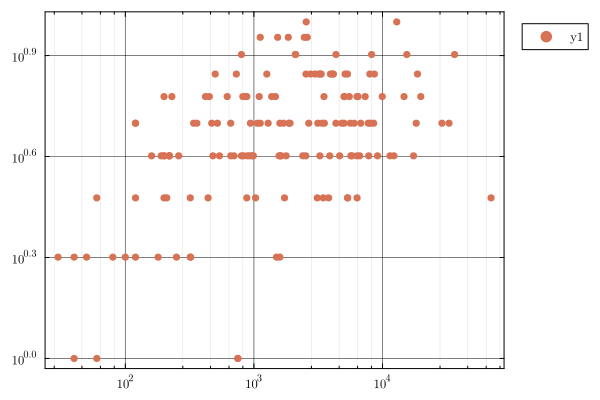

In [10]:
scatter(sum.([x[!,:N] for x in gd]), length.([x[!,:N] for x in gd]), xaxis = :log, yaxis = :log, alpha = 1.0)

In [11]:
logxs = log10.(sum.([x[!,:N] for x in gd]))
logys = log10.(length.([x[!,:N] for x in gd]));

In [12]:
df = DataFrame(y = logys, x = logxs);

In [13]:
glm = lm(@formula(y ~ x), df)

StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, LinearAlgebra.CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

y ~ 1 + x

Coefficients:
───────────────────────────────────────────────────────────────────────
                Coef.  Std. Error     t  Pr(>|t|)  Lower 95%  Upper 95%
───────────────────────────────────────────────────────────────────────
(Intercept)  0.208959   0.0681057  3.07    0.0026  0.0743815   0.343537
x            0.138771   0.0208788  6.65    <1e-09  0.097514    0.180028
───────────────────────────────────────────────────────────────────────

In [14]:
coef(glm)

2-element Vector{Float64}:
 0.2089591857133169
 0.13877079609769133

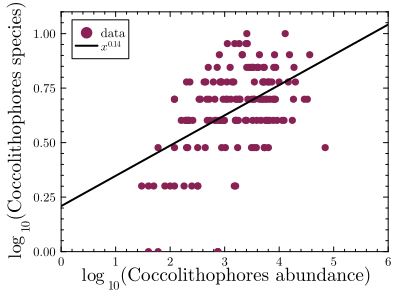

In [20]:
scatter(log10.(sum.([x[!,:N] for x in gd])), log10.(length.([x[!,:N] for x in gd])), alpha = 1.0, label = "data", c = pal[8]);
plot!(collect(0:6),coef(glm)[1] .+ collect(0:6) .*coef(glm)[2], label = L"x^{%$(round(coef(glm)[2],digits = 2))}", color = :black, lw = 2)
plot!(xlims = [0,6], ylims = [0,1.1], ylabel = L"$\log_{10}$(Coccolithophores species)", xlabel = L"$\log_{10}$(Coccolithophores abundance)", legend = :topleft,
    size = (400,300), grid = :none, minorgrid = :none)

Now let's make the rank-frequency plots.

In [21]:
si = sortperm(length.([x[!,:N] for x in gd]), rev = true);

In [25]:
cpal = [pal[i] for i in 0.0:1/length(gd):1];

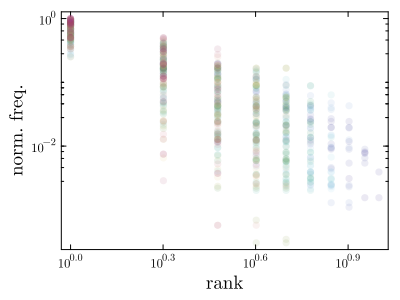

In [26]:
scatter(sort(gd[si[1]][!,:N]./sum(gd[si[1]][!,:N]), rev = true), xaxis = :log, yaxis = :log, color = cpal[1], alpha = 0.1)
for i in 2:length(gd)
    scatter!(sort(gd[si[i]][!,:N]./sum(gd[si[i]][!,:N]), rev = true), color = cpal[i], alpha = 0.1)
end
scatter!(legend = :none, ylabel = "norm. freq.", xlabel = "rank", size = (400,300), grid = :none, minorgrid = :none)